In [46]:
import torch
import torch.nn as nn
import numpy as np
import trimesh
import matplotlib.pyplot as plt
import pandas as pd
import os
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import random

In [47]:
def prepareDevice():
    device = torch.device("cpu")
    random.seed(42)
    os.environ['PYTHONHASHSEED'] = '42'
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Using CUDA")
    else:
        print("Using CPU")

    return device

device = prepareDevice()

Using CUDA


In [48]:
class Transform3DDataset(Dataset):
    def __init__(self, source_path, target_path, num_points=2048, augment=False, epoch_size=100):
        self.num_points = num_points
        self.augment = augment
        self.epoch_size = epoch_size
        
        self.source_mesh = trimesh.load(source_path)
        self.target_mesh = trimesh.load(target_path)
        
        self.source_vertices = self._normalize(self.source_mesh.vertices)
        self.target_vertices = self._normalize(self.target_mesh.vertices)
        
        self.source_mesh.vertices = self.source_vertices
        self.target_mesh.vertices = self.target_vertices

    def _normalize(self, vertices):
        centroid = np.mean(vertices, axis=0)
        vertices = vertices - centroid
        max_distance = np.max(np.sqrt(np.sum(vertices**2, axis=1)))
        vertices = vertices / max_distance
        return vertices

    def _augment(self, points):
        angles = np.random.uniform(-np.pi, np.pi, 3)
        
        Rx = np.array([[1, 0, 0],
                       [0, np.cos(angles[0]), -np.sin(angles[0])],
                       [0, np.sin(angles[0]), np.cos(angles[0])]])
                       
        Ry = np.array([[np.cos(angles[1]), 0, np.sin(angles[1])],
                       [0, 1, 0],
                       [-np.sin(angles[1]), 0, np.cos(angles[1])]])
                       
        Rz = np.array([[np.cos(angles[2]), -np.sin(angles[2]), 0],
                       [np.sin(angles[2]), np.cos(angles[2]), 0],
                       [0, 0, 1]])
                       
        R = Rz @ Ry @ Rx
        
        points = points @ R.T
        
        scale = np.random.uniform(0.8, 1.2)
        points *= scale
        
        return points

    def __len__(self):
        return self.epoch_size

    def __getitem__(self, idx):
        source_points, _ = trimesh.sample.sample_surface(self.source_mesh, self.num_points)
        target_points, _ = trimesh.sample.sample_surface(self.target_mesh, self.num_points)
        
        if self.augment:
            source_points = self._augment(source_points)
            
        return {
            'source': torch.tensor(source_points, dtype=torch.float32),
            'target': torch.tensor(target_points, dtype=torch.float32)
        }

In [49]:
DIR_MODELS = "modele"
path_teapot = os.path.join(DIR_MODELS, "teapot.obj")
path_bunny = os.path.join(DIR_MODELS, "bunny.obj")
path_dragon = os.path.join(DIR_MODELS, "dragon_small.obj")
path_armadillo = os.path.join(DIR_MODELS, "armadillo_small.obj")
path_asian_dragon = os.path.join(DIR_MODELS, "asian_dragon_really_small.obj") # Do testów na koniec

BATCH_SIZE = 4
NUM_POINTS = 2048 

dataset_bunny = Transform3DDataset(path_bunny, path_teapot, num_points=NUM_POINTS, augment=True)
dataset_dragon = Transform3DDataset(path_dragon, path_teapot, num_points=NUM_POINTS, augment=True)
dataset_armadillo = Transform3DDataset(path_armadillo, path_teapot, num_points=NUM_POINTS, augment=True)
dataset_asian_dragon = Transform3DDataset(path_asian_dragon, path_teapot, num_points=NUM_POINTS, augment=False)

loader_bunny = DataLoader(dataset_bunny, batch_size=BATCH_SIZE, shuffle=True)
loader_dragon = DataLoader(dataset_dragon, batch_size=BATCH_SIZE, shuffle=True)
loader_armadillo = DataLoader(dataset_armadillo, batch_size=BATCH_SIZE, shuffle=True)
loader_asian_dragon = DataLoader(dataset_asian_dragon, batch_size=BATCH_SIZE, shuffle=True)

batch = next(iter(loader_bunny))
print("Shape of source data (Bunny):", batch['source'].shape)
print("Shape of target data (Teapot):", batch['target'].shape)

Shape of source data (Bunny): torch.Size([4, 2048, 3])
Shape of target data (Teapot): torch.Size([4, 2048, 3])


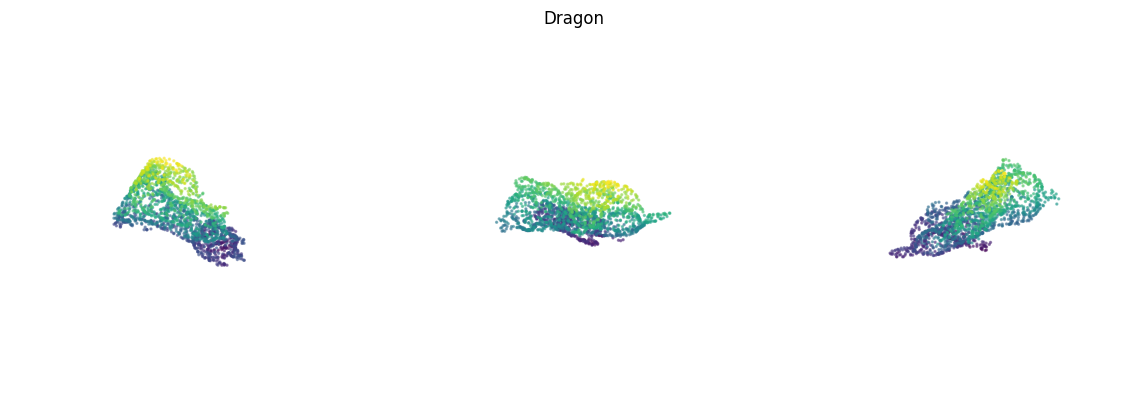

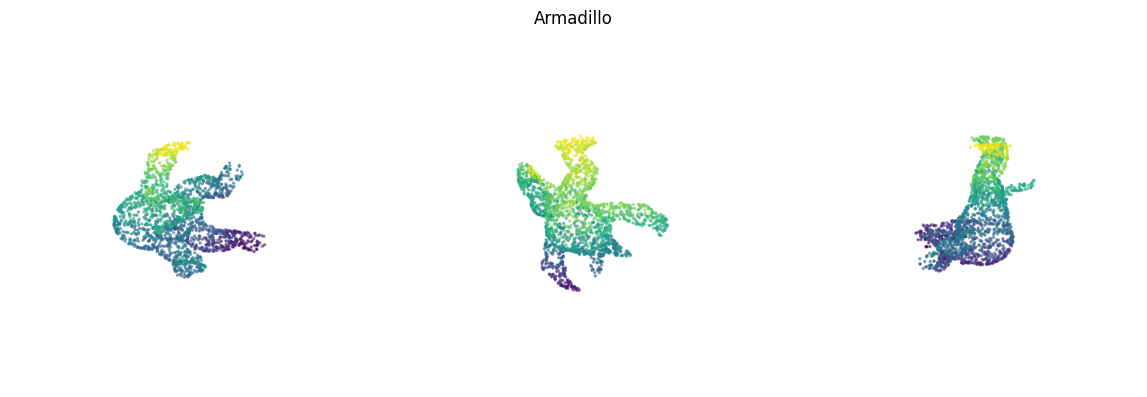

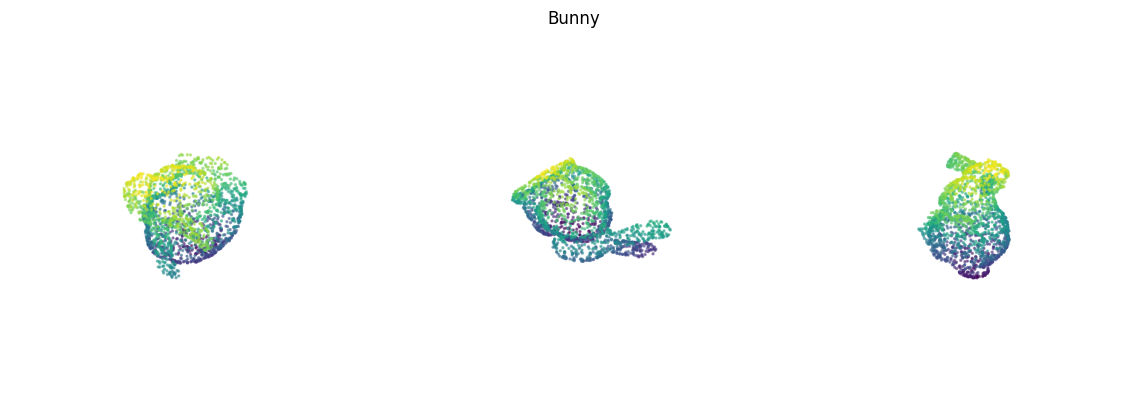

In [50]:
def visualize_dataset_sample(dataset, title_source="Input Object"):   
    fig = plt.figure(figsize=(12, 4))
    n = 3
    for idx in range(n):
        try:
            sample = dataset[idx]
            source_points = sample['source'].numpy()
            ax = fig.add_subplot(1, n, idx+1, projection='3d')
            ax.scatter(source_points[:, 0], source_points[:, 1], source_points[:, 2], s=2, c=source_points[:, 2], cmap='viridis', alpha=0.5)
            ax.set_xlim([-1, 1])
            ax.set_ylim([-1, 1])
            ax.set_zlim([-1, 1])
            ax.axis('off')
        except IndexError:
            print(f"Cannot retrieve sample with index {idx} from the dataset.")
    plt.suptitle(title_source)
    plt.tight_layout()
    plt.show()

visualize_dataset_sample(dataset_dragon, title_source="Dragon")
visualize_dataset_sample(dataset_armadillo, title_source="Armadillo")
visualize_dataset_sample(dataset_bunny, title_source="Bunny")

# Model

In [51]:
class PositionalEncoding(nn.Module):
    def __init__(self, num_frequencies=6):
        super().__init__()
        self.num_frequencies = num_frequencies

    def forward(self, x):
        encodings = [x] 
        
        for i in range(self.num_frequencies):
            for fn in [torch.sin, torch.cos]:
                encodings.append(fn((2.0 ** i) * np.pi * x))
                
        return torch.cat(encodings, dim=-1)

class VectorFieldMLP(nn.Module):
    def __init__(self, num_frequencies=6, hidden_dim=256):
        super().__init__()
        self.pe = PositionalEncoding(num_frequencies=num_frequencies)
        
        in_dim = 3 + 3 * 2 * num_frequencies
        
        # Deep MLP
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, 3)
        )

    def forward(self, x):
        x_encoded = self.pe(x)
        displacement = self.net(x_encoded)
        return displacement

In [ ]:
class VectorFieldMLPPro(nn.Module):
    def __init__(self, input_dim=3, num_freqs=10, hidden_dim=256, skip_layer=4):
        super().__init__()
        self.pe = PositionalEncoding(num_frequencies=num_freqs)
        
        in_dim = input_dim + input_dim * 2 * num_freqs
        
        self.block1 = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100)
        )
        
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim + in_dim, hidden_dim), 
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, 3) 
        )
        
        nn.init.normal_(self.block2[-1].weight, mean=0.0, std=1e-5)
        nn.init.constant_(self.block2[-1].bias, 0.0)

    def forward(self, x):
        x_encoded = self.pe(x)
        h = self.block1(x_encoded)
        h = torch.cat([h, x_encoded], dim=-1)
        displacement = self.block2(h)
        
        return displacement

In [53]:
# test
dummy_points = torch.randn(1, 2048, 3)
dummy_model = VectorFieldMLP(num_frequencies=6, hidden_dim=256)
vector_field = dummy_model(dummy_points)
transformed_points = dummy_points + vector_field
dummy_model_pro = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4)
vector_field_pro = dummy_model_pro(dummy_points)
transformed_points_pro = dummy_points + vector_field_pro
print("Input shape (Basic):", dummy_points.shape)
print("Output shape (Basic):", vector_field.shape)
print("Transformed shape (Basic):", transformed_points.shape)
print("Input shape (Pro):", dummy_points.shape)
print("Output shape (Pro):", vector_field_pro.shape)
print("Transformed shape (Pro):", transformed_points_pro.shape)

Input shape (Basic): torch.Size([1, 2048, 3])
Output shape (Basic): torch.Size([1, 2048, 3])
Transformed shape (Basic): torch.Size([1, 2048, 3])
Input shape (Pro): torch.Size([1, 2048, 3])
Output shape (Pro): torch.Size([1, 2048, 3])
Transformed shape (Pro): torch.Size([1, 2048, 3])


Trening

In [54]:
def chamfer_distance(p1, p2):
    dists_sq = torch.cdist(p1, p2) ** 2
    min_dist_p1_to_p2, _ = torch.min(dists_sq, dim=2) 
    min_dist_p2_to_p1, _ = torch.min(dists_sq, dim=1) 
    loss = torch.mean(min_dist_p1_to_p2) + torch.mean(min_dist_p2_to_p1)
    
    return loss

In [55]:
def train_model(model, dataloader, optimizer, num_epochs=100):
    model.to(device)

    for epoch in tqdm(range(num_epochs), desc="Training"):
        model.train()
        total_loss = 0.0
        total_cd = 0.0
        total_reg = 0.0
        
        for batch in (dataloader):
            source_points = batch['source'].to(device)
            target_points = batch['target'].to(device)

            optimizer.zero_grad()
            predicted_displacement = model(source_points)
            transformed_points = source_points + predicted_displacement

            loss_cd = chamfer_distance(transformed_points, target_points)
            loss_reg = torch.mean(predicted_displacement**2)
            loss = 1000.0 * loss_cd + 1.0 * loss_reg
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_cd += loss_cd.item()
            total_reg += loss_reg.item()
        
        avg_loss = total_loss / len(dataloader)
        avg_cd = total_cd / len(dataloader)
        avg_reg = total_reg / len(dataloader)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1} | Total Loss: {avg_loss:.4f} | Chamfer: {avg_cd:.6f} | Reg: {avg_reg:.6f}")

In [56]:
def visualize_morphing(model, dataset, device, title="Transformation"):
    model.eval() 
    sample = dataset[0]
    source_points = sample['source'].unsqueeze(0).to(device)
    
    with torch.no_grad():
        final_displacement = model(source_points)
    
    source_points_np = source_points[0].cpu().numpy()
    displacement_np = final_displacement[0].cpu().numpy()

    steps = [0.0, 0.33, 0.66, 1.0] 
    
    fig = plt.figure(figsize=(15, 5))

    for i, t in enumerate(steps):
        ax = fig.add_subplot(1, 4, i+1, projection='3d')

        current_points = source_points_np + (displacement_np * t)

        ax.scatter(current_points[:, 0], current_points[:, 1], current_points[:, 2], 
                   s=2, c=current_points[:, 2], cmap='viridis', alpha=0.8)
        
        if t == 0.0:
            step_title = f"{title}\nStart (t=0)"
        elif t == 1.0:
            step_title = f"{title}\nEnd (t=1)"
        else:
            step_title = f"{title}\nIntermediate step (t={t:.2f})"
            
        ax.set_title(step_title)
        
        ax.set_xlim([-1, 1])
        ax.set_ylim([-1, 1])
        ax.set_zlim([-1, 1])
        ax.axis('off')

    plt.tight_layout()
    plt.show()

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 45.8689 | Chamfer: 0.045849 | Reg: 0.019684
Epoch 10 | Total Loss: 4.4505 | Chamfer: 0.004353 | Reg: 0.097267
Epoch 20 | Total Loss: 3.2332 | Chamfer: 0.003127 | Reg: 0.106491
Epoch 30 | Total Loss: 2.7578 | Chamfer: 0.002647 | Reg: 0.110455
Epoch 40 | Total Loss: 2.6059 | Chamfer: 0.002484 | Reg: 0.121458
Epoch 50 | Total Loss: 2.3556 | Chamfer: 0.002238 | Reg: 0.117744
Epoch 60 | Total Loss: 2.5532 | Chamfer: 0.002438 | Reg: 0.115456
Epoch 70 | Total Loss: 2.4559 | Chamfer: 0.002336 | Reg: 0.119653
Epoch 80 | Total Loss: 2.2517 | Chamfer: 0.002130 | Reg: 0.121659
Epoch 90 | Total Loss: 2.2618 | Chamfer: 0.002142 | Reg: 0.119694
Epoch 100 | Total Loss: 2.1234 | Chamfer: 0.002005 | Reg: 0.117987
Epoch 110 | Total Loss: 2.1557 | Chamfer: 0.002037 | Reg: 0.118886
Epoch 120 | Total Loss: 2.1002 | Chamfer: 0.001976 | Reg: 0.124679
Epoch 130 | Total Loss: 2.1321 | Chamfer: 0.002008 | Reg: 0.123724
Epoch 140 | Total Loss: 2.0353 | Chamfer: 0.001920 | Reg: 0.115400
Epoch

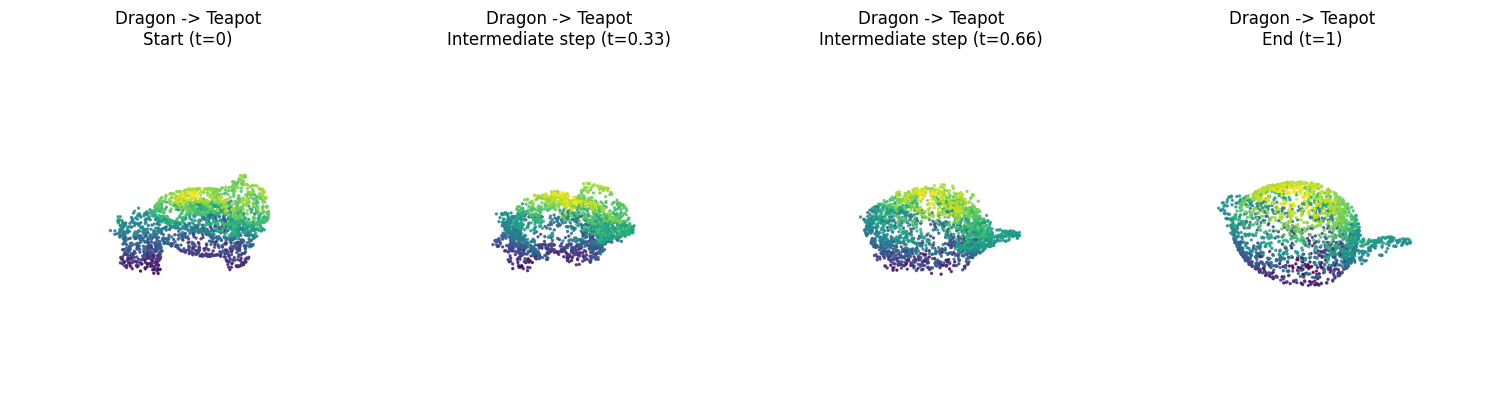

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 25.9282 | Chamfer: 0.025917 | Reg: 0.011524
Epoch 10 | Total Loss: 2.5387 | Chamfer: 0.002517 | Reg: 0.021775
Epoch 20 | Total Loss: 2.0476 | Chamfer: 0.002027 | Reg: 0.020949
Epoch 30 | Total Loss: 1.9725 | Chamfer: 0.001953 | Reg: 0.019741
Epoch 40 | Total Loss: 1.9233 | Chamfer: 0.001903 | Reg: 0.020754
Epoch 50 | Total Loss: 1.9351 | Chamfer: 0.001915 | Reg: 0.020562
Epoch 60 | Total Loss: 1.8775 | Chamfer: 0.001857 | Reg: 0.020898
Epoch 70 | Total Loss: 1.8919 | Chamfer: 0.001871 | Reg: 0.021212
Epoch 80 | Total Loss: 1.8856 | Chamfer: 0.001864 | Reg: 0.021140
Epoch 90 | Total Loss: 1.8497 | Chamfer: 0.001828 | Reg: 0.021734
Epoch 100 | Total Loss: 1.8546 | Chamfer: 0.001833 | Reg: 0.021982
Epoch 110 | Total Loss: 1.8437 | Chamfer: 0.001822 | Reg: 0.022004
Epoch 120 | Total Loss: 1.8474 | Chamfer: 0.001824 | Reg: 0.023014
Epoch 130 | Total Loss: 1.8202 | Chamfer: 0.001796 | Reg: 0.023851
Epoch 140 | Total Loss: 1.8441 | Chamfer: 0.001820 | Reg: 0.024629
Epoch

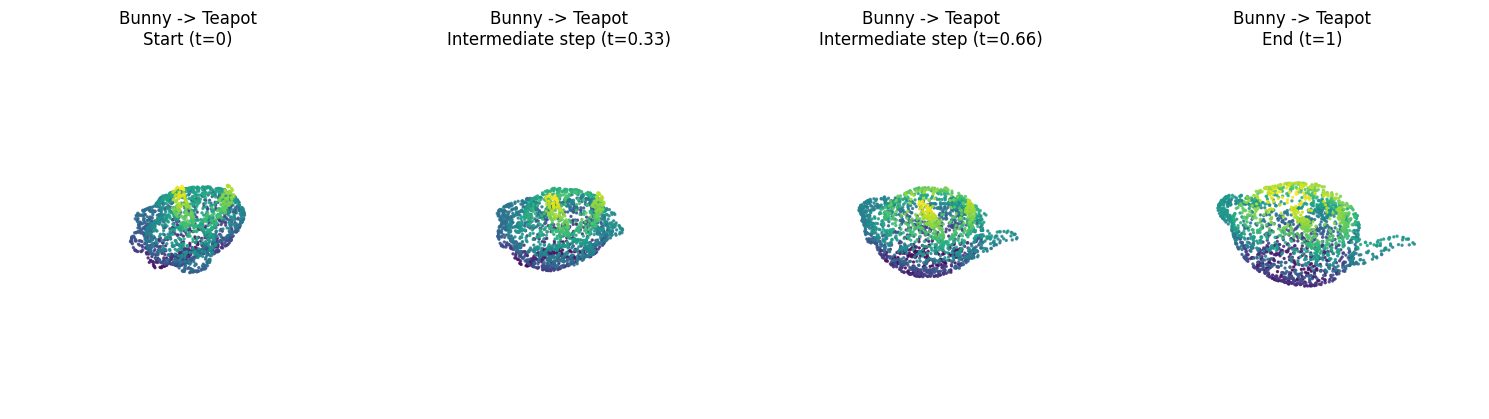

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 48.6518 | Chamfer: 0.048633 | Reg: 0.018395
Epoch 10 | Total Loss: 4.9640 | Chamfer: 0.004877 | Reg: 0.087422
Epoch 20 | Total Loss: 3.5032 | Chamfer: 0.003408 | Reg: 0.095490
Epoch 30 | Total Loss: 3.0605 | Chamfer: 0.002961 | Reg: 0.099765
Epoch 40 | Total Loss: 2.5912 | Chamfer: 0.002491 | Reg: 0.099909
Epoch 50 | Total Loss: 2.4906 | Chamfer: 0.002389 | Reg: 0.101486
Epoch 60 | Total Loss: 2.5769 | Chamfer: 0.002473 | Reg: 0.103606
Epoch 70 | Total Loss: 2.3888 | Chamfer: 0.002283 | Reg: 0.105576
Epoch 80 | Total Loss: 2.3388 | Chamfer: 0.002231 | Reg: 0.107309
Epoch 90 | Total Loss: 2.3028 | Chamfer: 0.002191 | Reg: 0.111848
Epoch 100 | Total Loss: 2.2022 | Chamfer: 0.002095 | Reg: 0.107617
Epoch 110 | Total Loss: 2.1487 | Chamfer: 0.002035 | Reg: 0.113684
Epoch 120 | Total Loss: 2.1489 | Chamfer: 0.002034 | Reg: 0.115068
Epoch 130 | Total Loss: 2.0915 | Chamfer: 0.001976 | Reg: 0.115891
Epoch 140 | Total Loss: 2.0732 | Chamfer: 0.001961 | Reg: 0.111916
Epoch

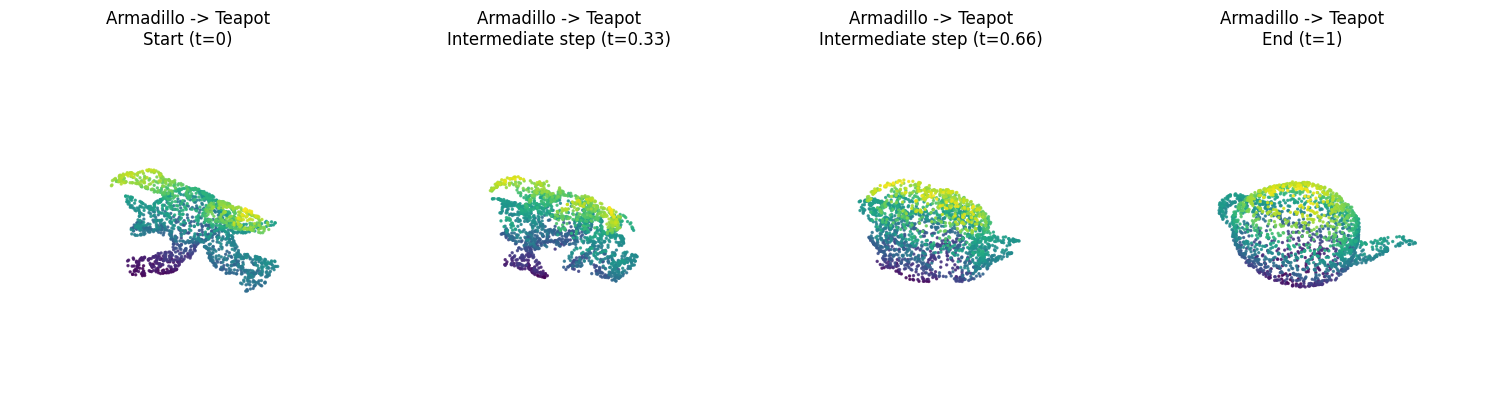

In [57]:
model_dragon_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)
model_bunny_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)
model_armadillo_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)

for model, loader, name in zip([model_dragon_basic, model_bunny_basic, model_armadillo_basic], [loader_dragon, loader_bunny, loader_armadillo], ["Dragon -> Teapot", "Bunny -> Teapot", "Armadillo -> Teapot"]):
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    train_model(model, loader, optimizer, num_epochs=500)
    model.eval()
    visualize_morphing(model, loader.dataset, device, title=name)

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 69.7907 | Chamfer: 0.069784 | Reg: 0.006759
Epoch 10 | Total Loss: 7.1222 | Chamfer: 0.007021 | Reg: 0.101496
Epoch 20 | Total Loss: 3.6959 | Chamfer: 0.003587 | Reg: 0.108711
Epoch 30 | Total Loss: 2.9924 | Chamfer: 0.002882 | Reg: 0.110176
Epoch 40 | Total Loss: 2.5466 | Chamfer: 0.002442 | Reg: 0.104484
Epoch 50 | Total Loss: 2.3335 | Chamfer: 0.002227 | Reg: 0.106172
Epoch 60 | Total Loss: 2.2393 | Chamfer: 0.002133 | Reg: 0.106435
Epoch 70 | Total Loss: 2.2114 | Chamfer: 0.002101 | Reg: 0.110661
Epoch 80 | Total Loss: 2.1134 | Chamfer: 0.001999 | Reg: 0.114805
Epoch 90 | Total Loss: 1.9595 | Chamfer: 0.001854 | Reg: 0.105932
Epoch 100 | Total Loss: 1.9729 | Chamfer: 0.001861 | Reg: 0.112193
Epoch 110 | Total Loss: 1.9314 | Chamfer: 0.001821 | Reg: 0.110029
Epoch 120 | Total Loss: 1.9709 | Chamfer: 0.001860 | Reg: 0.110460
Epoch 130 | Total Loss: 1.8440 | Chamfer: 0.001727 | Reg: 0.116745
Epoch 140 | Total Loss: 1.8049 | Chamfer: 0.001692 | Reg: 0.112815
Epoch

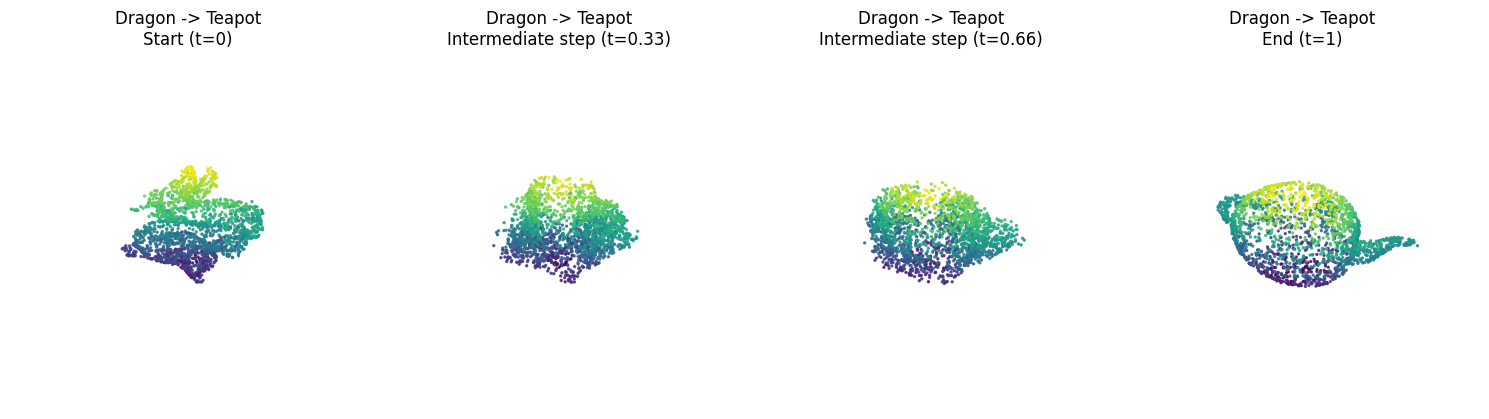

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 44.6919 | Chamfer: 0.044687 | Reg: 0.005240
Epoch 10 | Total Loss: 3.6412 | Chamfer: 0.003618 | Reg: 0.023130
Epoch 20 | Total Loss: 2.4997 | Chamfer: 0.002476 | Reg: 0.023402
Epoch 30 | Total Loss: 2.1801 | Chamfer: 0.002156 | Reg: 0.024404
Epoch 40 | Total Loss: 2.0635 | Chamfer: 0.002039 | Reg: 0.024195
Epoch 50 | Total Loss: 1.9880 | Chamfer: 0.001964 | Reg: 0.023651
Epoch 60 | Total Loss: 1.9516 | Chamfer: 0.001927 | Reg: 0.024454
Epoch 70 | Total Loss: 1.8940 | Chamfer: 0.001868 | Reg: 0.025503
Epoch 80 | Total Loss: 1.8697 | Chamfer: 0.001845 | Reg: 0.024529
Epoch 90 | Total Loss: 1.8376 | Chamfer: 0.001810 | Reg: 0.027398
Epoch 100 | Total Loss: 1.8316 | Chamfer: 0.001804 | Reg: 0.027176
Epoch 110 | Total Loss: 1.7979 | Chamfer: 0.001769 | Reg: 0.028954
Epoch 120 | Total Loss: 1.7508 | Chamfer: 0.001719 | Reg: 0.031802
Epoch 130 | Total Loss: 1.7544 | Chamfer: 0.001723 | Reg: 0.031928
Epoch 140 | Total Loss: 1.7246 | Chamfer: 0.001689 | Reg: 0.035123
Epoch

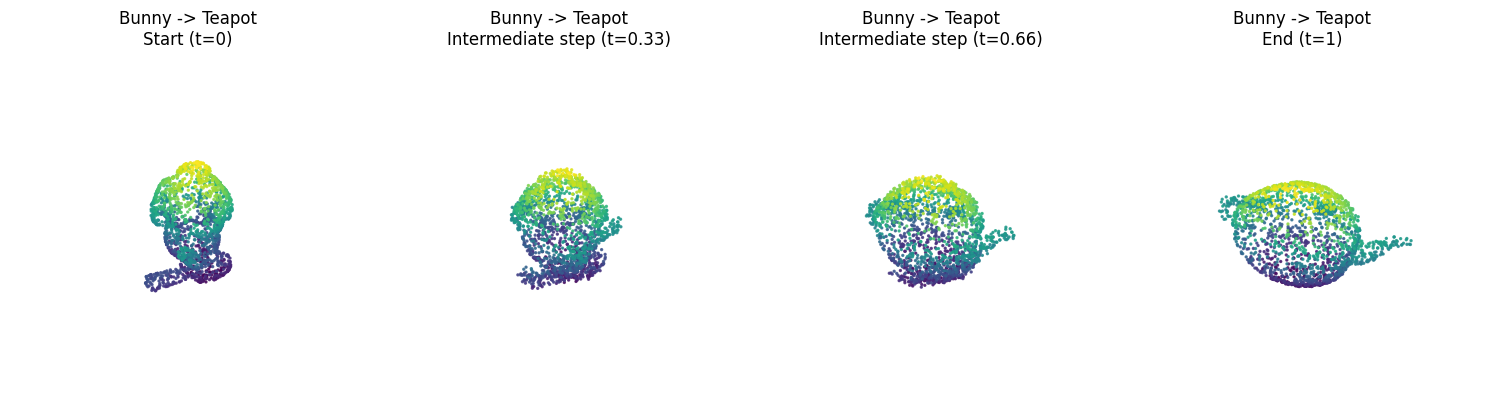

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 76.6141 | Chamfer: 0.076607 | Reg: 0.007088
Epoch 10 | Total Loss: 7.2369 | Chamfer: 0.007180 | Reg: 0.057325
Epoch 20 | Total Loss: 4.6615 | Chamfer: 0.004582 | Reg: 0.079255
Epoch 30 | Total Loss: 3.4191 | Chamfer: 0.003324 | Reg: 0.095193
Epoch 40 | Total Loss: 2.9008 | Chamfer: 0.002800 | Reg: 0.101039
Epoch 50 | Total Loss: 2.6310 | Chamfer: 0.002526 | Reg: 0.105160
Epoch 60 | Total Loss: 2.3732 | Chamfer: 0.002262 | Reg: 0.111112
Epoch 70 | Total Loss: 2.2713 | Chamfer: 0.002163 | Reg: 0.107855
Epoch 80 | Total Loss: 2.2038 | Chamfer: 0.002092 | Reg: 0.112196
Epoch 90 | Total Loss: 2.1227 | Chamfer: 0.002016 | Reg: 0.107158
Epoch 100 | Total Loss: 2.0599 | Chamfer: 0.001947 | Reg: 0.112514
Epoch 110 | Total Loss: 2.0339 | Chamfer: 0.001923 | Reg: 0.110611
Epoch 120 | Total Loss: 2.0264 | Chamfer: 0.001917 | Reg: 0.109567
Epoch 130 | Total Loss: 1.9255 | Chamfer: 0.001816 | Reg: 0.109494
Epoch 140 | Total Loss: 1.9563 | Chamfer: 0.001846 | Reg: 0.110033
Epoch

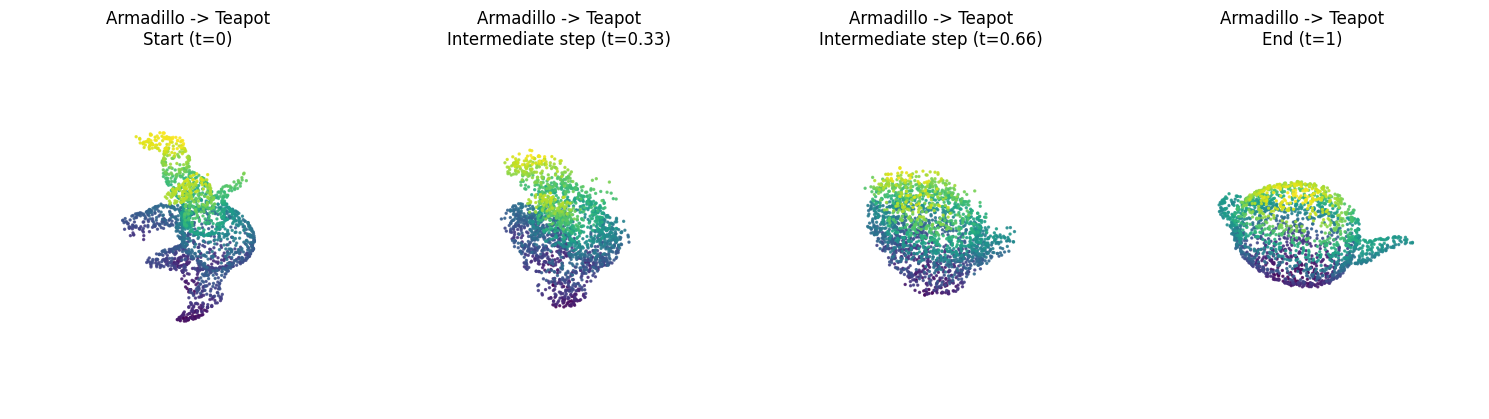

In [58]:
model_dragon = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)
model_bunny = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)
model_armadillo = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)

for model, loader, name in zip([model_dragon, model_bunny, model_armadillo], [loader_dragon, loader_bunny, loader_armadillo], ["Dragon -> Teapot", "Bunny -> Teapot", "Armadillo -> Teapot"]):
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    train_model(model, loader, optimizer, num_epochs=500)
    model.eval()
    visualize_morphing(model, loader.dataset, device, title=name)

In [59]:
torch.save(model_dragon_basic.state_dict(), 'model_dragon_basic.pth')
torch.save(model_bunny_basic.state_dict(), 'model_bunny_basic.pth')
torch.save(model_armadillo_basic.state_dict(), 'model_armadillo_basic.pth')
torch.save(model_dragon.state_dict(), 'model_dragon_pro.pth')
torch.save(model_bunny.state_dict(), 'model_bunny_pro.pth')
torch.save(model_armadillo.state_dict(), 'model_armadillo_pro.pth')

In [60]:
def save_reconstructed_mesh(model, source_mesh_path, output_path, device):
    model.eval() 
    source_mesh = trimesh.load(source_mesh_path)

    vertices = source_mesh.vertices
    centroid = vertices.mean(axis=0)
    vertices = vertices - centroid
    max_distance = np.max(np.sqrt(np.sum(vertices**2, axis=1)))
    vertices = vertices / max_distance

    vertices_tensor = torch.tensor(vertices, dtype=torch.float32).unsqueeze(0).to(device)
    
    with torch.no_grad():
        displacement = model(vertices_tensor)
        
    deformed_vertices = vertices_tensor + displacement
    deformed_vertices_np = deformed_vertices.squeeze(0).cpu().numpy()
    
    reconstructed_mesh = trimesh.Trimesh(vertices=deformed_vertices_np, 
                                         faces=source_mesh.faces)
    
    reconstructed_mesh.export(output_path)
    print(f"Saved reconstructed mesh to: {output_path}")

In [61]:
save_reconstructed_mesh(model_dragon_basic, "modele/dragon_small.obj", "output/reconstructed_dragon_basic.obj", device)
save_reconstructed_mesh(model_bunny_basic, "modele/bunny.obj", "output/reconstructed_bunny_basic.obj", device)
save_reconstructed_mesh(model_armadillo_basic, "modele/armadillo_small.obj", "output/reconstructed_armadillo_basic.obj", device)
save_reconstructed_mesh(model_dragon, "modele/dragon_small.obj", "output/reconstructed_dragon_pro.obj", device)
save_reconstructed_mesh(model_bunny, "modele/bunny.obj", "output/reconstructed_bunny_pro.obj", device)
save_reconstructed_mesh(model_armadillo, "modele/armadillo_small.obj", "output/reconstructed_armadillo_pro.obj", device)

Saved reconstructed mesh to: output/reconstructed_dragon_basic.obj
Saved reconstructed mesh to: output/reconstructed_bunny_basic.obj
Saved reconstructed mesh to: output/reconstructed_armadillo_basic.obj
Saved reconstructed mesh to: output/reconstructed_dragon_pro.obj
Saved reconstructed mesh to: output/reconstructed_bunny_pro.obj
Saved reconstructed mesh to: output/reconstructed_armadillo_pro.obj


In [62]:
model_dragon_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_bunny_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_armadillo_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_dragon = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_bunny = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_armadillo = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_dragon_basic.load_state_dict(torch.load('model_dragon_basic.pth', map_location=device))
model_bunny_basic.load_state_dict(torch.load('model_bunny_basic.pth', map_location=device))
model_armadillo_basic.load_state_dict(torch.load('model_armadillo_basic.pth', map_location=device))
model_dragon.load_state_dict(torch.load('model_dragon_pro.pth', map_location=device))
model_bunny.load_state_dict(torch.load('model_bunny_pro.pth', map_location=device))
model_armadillo.load_state_dict(torch.load('model_armadillo_pro.pth', map_location=device))

<All keys matched successfully>

# Asian Dragon

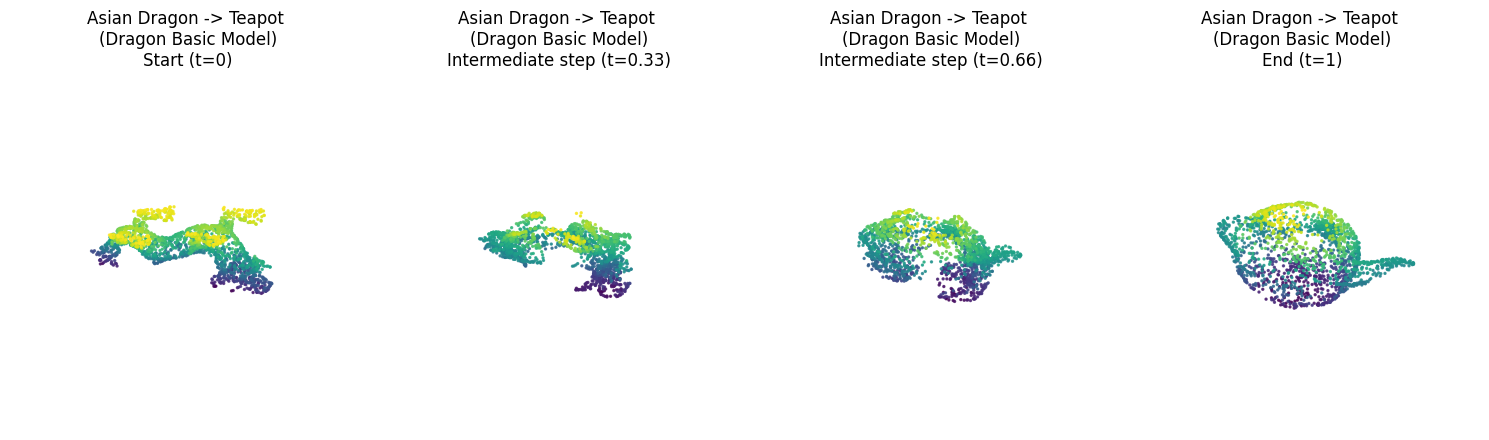

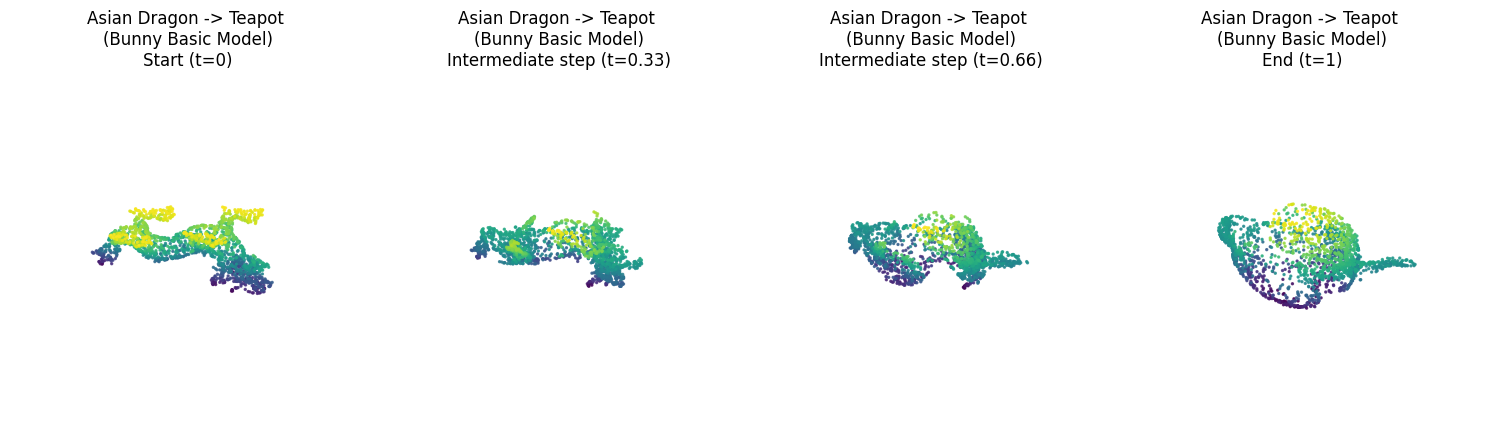

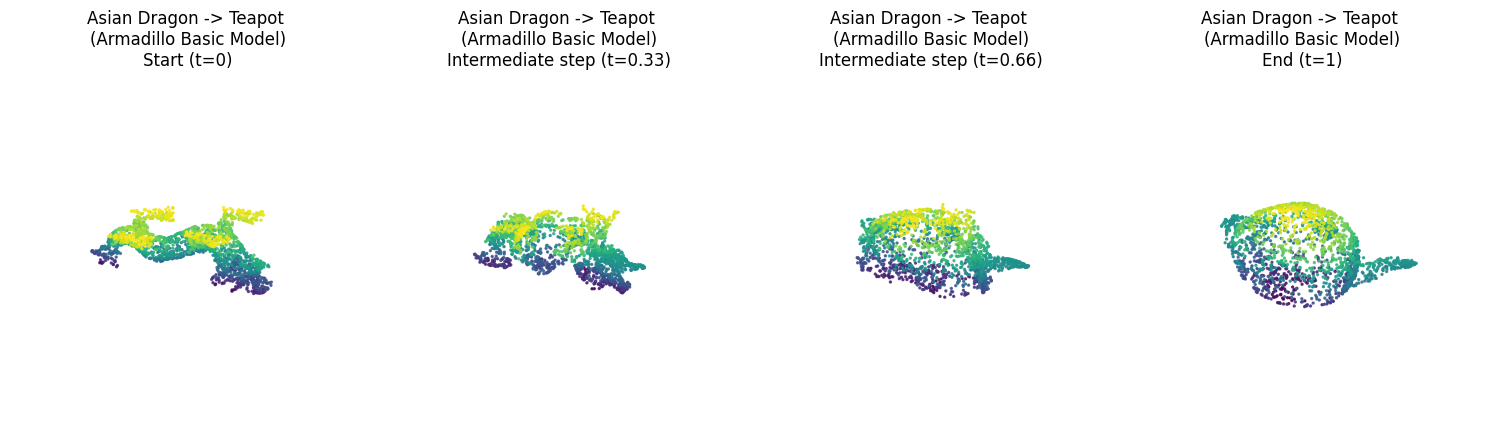

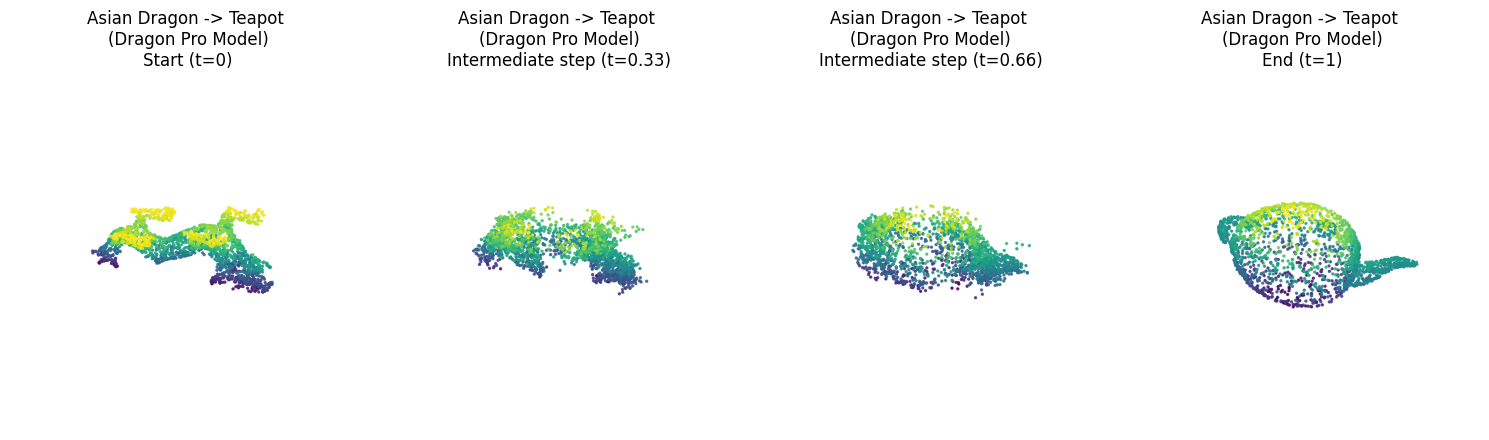

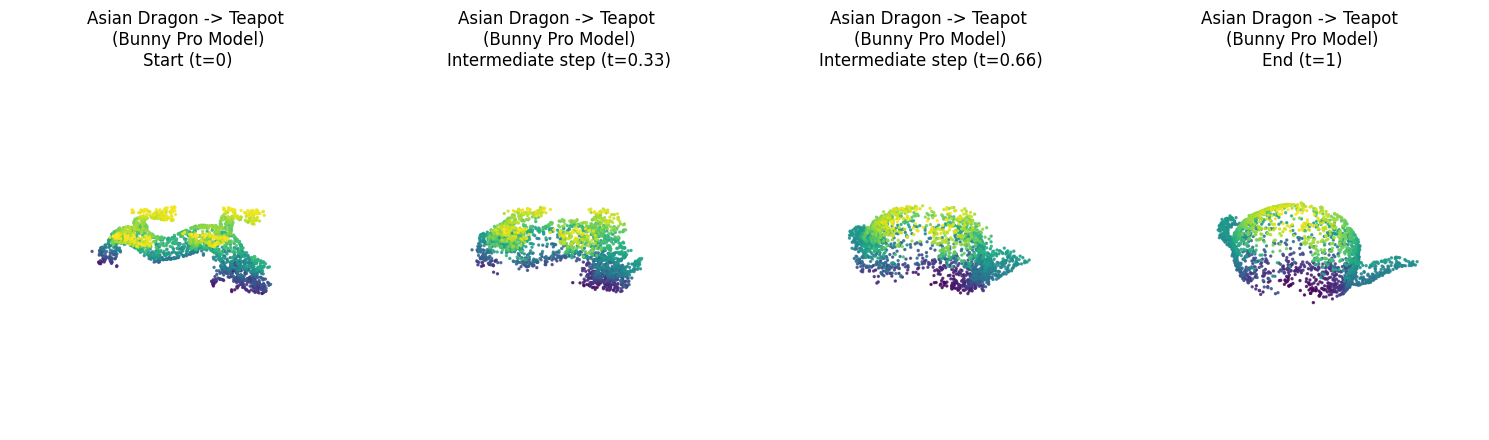

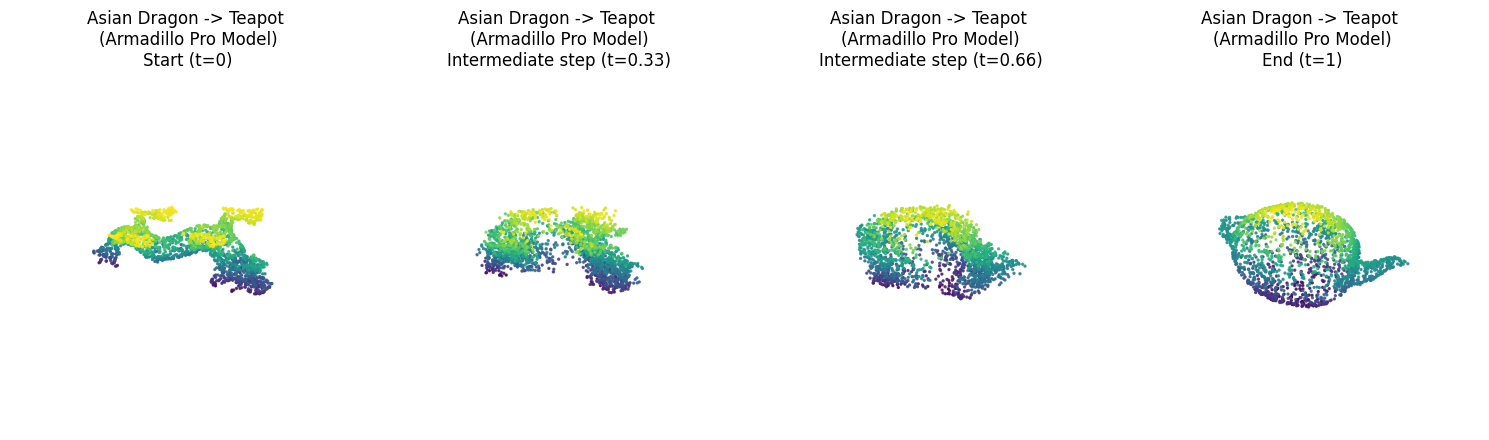

In [63]:
with torch.no_grad():
    visualize_morphing(model_dragon_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Dragon Basic Model)")
    visualize_morphing(model_bunny_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Bunny Basic Model)")
    visualize_morphing(model_armadillo_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Armadillo Basic Model)")
    visualize_morphing(model_dragon, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Dragon Pro Model)")
    visualize_morphing(model_bunny, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Bunny Pro Model)")
    visualize_morphing(model_armadillo, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Armadillo Pro Model)")

# Metryki

In [68]:
def compute_metrics(transformed_pts, target_pts, threshold=0.05):
    chamfer = chamfer_distance(transformed_pts, target_pts)
    
    dists = torch.cdist(transformed_pts, target_pts)
    min_dist_to_target, _ = torch.min(dists, dim=2) 
    min_dist_to_source, _ = torch.min(dists, dim=1) 
    
    precision = (min_dist_to_target < threshold).float().mean().item()
    recall = (min_dist_to_source < threshold).float().mean().item()
    
    epsilon = 1e-8
    dice = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    iou = dice / (2 - dice + epsilon)
    
    return iou, dice, chamfer.item()


def evaluate_model(model, dataset, device, threshold=0.05):
    model.eval() 
    with torch.no_grad():
        sample = dataset[0]
        
        source_points = sample['source'].unsqueeze(0).to(device)
        target_points = sample['target'].unsqueeze(0).to(device)
        
        displacement = model(source_points)
        transformed_points = source_points + displacement
        
        iou, dice, chamfer = compute_metrics(transformed_points, target_points, threshold)
        
        return iou, dice, chamfer

threshold_val = 0.03

scenarios_1 = [[
    ("bunny basic flow", model_bunny_basic, dataset_bunny),
    ("dragon basic flow", model_dragon_basic, dataset_dragon),
    ("armadillo basic flow", model_armadillo_basic, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny_basic, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon_basic, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo_basic, dataset_asian_dragon)
], "Basic"]

scenarios_2 = [[
    ("bunny flow", model_bunny, dataset_bunny),
    ("dragon flow", model_dragon, dataset_dragon),
    ("armadillo flow", model_armadillo, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo, dataset_asian_dragon)
], "Pro"]

for scenarios in [scenarios_1, scenarios_2]:
    results = []
    scenario_name = scenarios[1]
    for name, model, dataset in scenarios[0]:
        iou, dice, cd = evaluate_model(model, dataset, device, threshold=threshold_val)
        results.append({
            "Method": name,
            "IoU": round(iou, 4),
            "Dice": round(dice, 4),
            "Chamfer": round(cd, 6) 
        })

    df_results = pd.DataFrame(results)
    df_results.set_index("Method", inplace=True)

    print(f"\n--- {scenario_name} Results Table ---")
    display(df_results)


--- Basic Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny basic flow,0.5156,0.6804,0.001683
dragon basic flow,0.5227,0.6866,0.001623
armadillo basic flow,0.5047,0.6708,0.001753
bunny flow asian dragon,0.4223,0.5938,0.005187
dragon flow asian dragon,0.4672,0.6369,0.001902
armadillo flow asian dragon,0.5006,0.6672,0.001742



--- Pro Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny flow,0.5777,0.7323,0.001412
dragon flow,0.5503,0.7099,0.001480
armadillo flow,0.5447,0.7053,0.001487
bunny flow asian dragon,0.4487,0.6195,0.005008
dragon flow asian dragon,0.5472,0.7074,0.001561
armadillo flow asian dragon,0.5236,0.6873,0.001597


In [72]:
def voxelize(points, resolution=32):
    voxel_grid = np.zeros((resolution, resolution, resolution), dtype=bool)

    norm_points = (points + 1.0) * 0.5 * (resolution - 1)
    norm_points = norm_points.astype(int)

    mask = (norm_points[:, 0] >= 0) & (norm_points[:, 0] < resolution) & \
           (norm_points[:, 1] >= 0) & (norm_points[:, 1] < resolution) & \
           (norm_points[:, 2] >= 0) & (norm_points[:, 2] < resolution)
    norm_points = norm_points[mask]

    voxel_grid[norm_points[:, 0], norm_points[:, 1], norm_points[:, 2]] = True
    return voxel_grid

def calculate_iou_dice(pred_points, target_points, res=32):
    if pred_points.dim() == 3:
        pred_points = pred_points.squeeze(0)
    if target_points.dim() == 3:
        target_points = target_points.squeeze(0)
    v_pred = voxelize(pred_points.detach().cpu().numpy(), res)
    v_target = voxelize(target_points.detach().cpu().numpy(), res)

    intersection = np.logical_and(v_pred, v_target).sum()
    union = np.logical_or(v_pred, v_target).sum()
    sum_volumes = v_pred.sum() + v_target.sum()

    iou = intersection / union if union > 0 else 0
    dice = (2 * intersection) / sum_volumes if sum_volumes > 0 else 0

    return iou, dice


def evaluate_model(model, dataset, device, resolution=32):
    model.eval() 
    with torch.no_grad(): 
        sample = dataset[0]
        
        source_points = sample['source'].unsqueeze(0).to(device)
        target_points = sample['target'].unsqueeze(0).to(device)
        
        displacement = model(source_points)
        transformed_points = source_points + displacement
        
        chamfer = chamfer_distance(transformed_points, target_points)
        chamfer_val = chamfer.item() if torch.is_tensor(chamfer) else chamfer
        
        iou, dice = calculate_iou_dice(transformed_points, target_points, res=resolution)
        
        return iou, dice, chamfer_val

grid_res = 32 

scenarios_1 = [[
    ("bunny basic flow", model_bunny_basic, dataset_bunny),
    ("dragon basic flow", model_dragon_basic, dataset_dragon),
    ("armadillo basic flow", model_armadillo_basic, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny_basic, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon_basic, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo_basic, dataset_asian_dragon)
], "Basic"]

scenarios_2 = [[
    ("bunny flow", model_bunny, dataset_bunny),
    ("dragon flow", model_dragon, dataset_dragon),
    ("armadillo flow", model_armadillo, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo, dataset_asian_dragon)
], "Pro"]

for i, scenarios in enumerate([scenarios_1, scenarios_2]):
    results = []
    scenario_name = scenarios[1]
    
    for name, model, dataset in scenarios[0]:
        iou, dice, cd = evaluate_model(model, dataset, device, resolution=grid_res)
        results.append({
            "Method": name,
            "IoU": round(iou, 4),
            "Dice": round(dice, 4),
            "Chamfer": round(cd, 6) 
        })

    df_results = pd.DataFrame(results)
    df_results.set_index("Method", inplace=True)

    print(f"\n--- {scenario_name} Results Table ---")
    display(df_results)


--- Basic Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny basic flow,0.5891,0.7414,0.001497
dragon basic flow,0.5702,0.7263,0.001769
armadillo basic flow,0.5830,0.7366,0.001677
bunny flow asian dragon,0.4401,0.6112,0.004806
dragon flow asian dragon,0.5458,0.7062,0.001862
armadillo flow asian dragon,0.5531,0.7122,0.001856



--- Pro Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny flow,0.5968,0.7475,0.001496
dragon flow,0.6260,0.7700,0.001424
armadillo flow,0.6127,0.7598,0.001541
bunny flow asian dragon,0.4691,0.6386,0.005574
dragon flow asian dragon,0.5851,0.7382,0.001558
armadillo flow asian dragon,0.6073,0.7557,0.001585


In [73]:
save_reconstructed_mesh(model_dragon_basic, path_asian_dragon, "output/reconstructed_asian_dragon_basic.obj", device)
save_reconstructed_mesh(model_bunny_basic, path_asian_dragon, "output/reconstructed_asian_bunny_basic.obj", device)
save_reconstructed_mesh(model_armadillo_basic, path_asian_dragon, "output/reconstructed_asian_armadillo_basic.obj", device)
save_reconstructed_mesh(model_dragon, path_asian_dragon, "output/reconstructed_asian_dragon_pro.obj", device)
save_reconstructed_mesh(model_bunny, path_asian_dragon, "output/reconstructed_asian_bunny_pro.obj", device)
save_reconstructed_mesh(model_armadillo, path_asian_dragon, "output/reconstructed_asian_armadillo_pro.obj", device)

Saved reconstructed mesh to: output/reconstructed_asian_dragon_basic.obj
Saved reconstructed mesh to: output/reconstructed_asian_bunny_basic.obj
Saved reconstructed mesh to: output/reconstructed_asian_armadillo_basic.obj
Saved reconstructed mesh to: output/reconstructed_asian_dragon_pro.obj
Saved reconstructed mesh to: output/reconstructed_asian_bunny_pro.obj
Saved reconstructed mesh to: output/reconstructed_asian_armadillo_pro.obj
